# Tugas 2 — Pendekatan Non-Deep Learning: Inspeksi Kemasan Kubus Gingerbread 3D

Notebook ini mendokumentasikan alur kerja lengkap yang **kami** bangun untuk menyelesaikan Tugas 2 tanpa menggunakan model *deep learning*. Setiap potongan kode didahului penjelasan singkat mengenai apa yang **kami** lakukan pada tahapan pemrosesan tersebut serta alasan desainnya.

### 1. Inisialisasi Lingkungan dan Pemuatan Dataset
Kami menyiapkan jalur direktori proyek serta memuat fungsi modular dari paket `src.task2_non_dl`, termasuk *geometry solver* dan *template-matching detector*, kemudian mengekstrak kamus desain referensi serta indeks anotasi dari arsip pelatihan.

In [1]:
import io
import json
import sys
import time
import zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "task2_non_dl").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.task2_non_dl import (
    CANONICAL_FACE_SIZE,
    align_and_score_cookie,
    compute_vanishing_center,
    extract_cube_hexagon,
    fit_background_model,
    predict_cube_non_dl,
    prepare_reference_cache,
    rectify_face,
    segment_cube_faces,
    segment_face_cookies,
)
from src.task2_non_dl.evaluate_and_visualize import (
    FACES,
    cube_columns,
    evaluate_cube_dataframe,
    load_zip_references,
    validate_cube_predictions,
)

TRAIN_ZIP = ROOT / "data" / "gingerbread_seed2026_students_training.zip"
HIDDEN_ZIP = ROOT / "data" / "hidden_students.zip"

with zipfile.ZipFile(TRAIN_ZIP) as zf:
    references = load_zip_references(zf)
    annotations = json.loads(zf.read("cube_annotations.json"))

print(f"Total citra kubus berlabel: {len(annotations)}")
print(f"Referensi desain tersedia : {[(k, v['name'], v['rgba'].shape) for k, v in references.items()]}")

Total citra kubus berlabel: 100
Referensi desain tersedia : [(1, 'blue_wizard', (512, 256, 4))]


### 2. Rekonstruksi Geometri 3D Kubus dan Rektifikasi Perspektif
Kami terlebih dahulu memodelkan iluminasi latar belakang memakai regresi kuadratik-radial pada piksel tepi luar citra agar bayangan gradasi tersingkirkan, lalu mengekstraksi *hexagon* pembatas luar kubus pada ketelitian sub-piksel memakai `cv2.fitLine`. Selanjutnya, kami menghitung koordinat pertemuan tiga rusuk dalam (`v_center`) melalui perpotongan garis paralel homogen (*vanishing point*), membagi kubus menjadi sisi `front`, `right`, dan `top`, serta meluruskan masing-masing sisi ke ukuran kanonik `384x384` dengan transformasi *homography*.

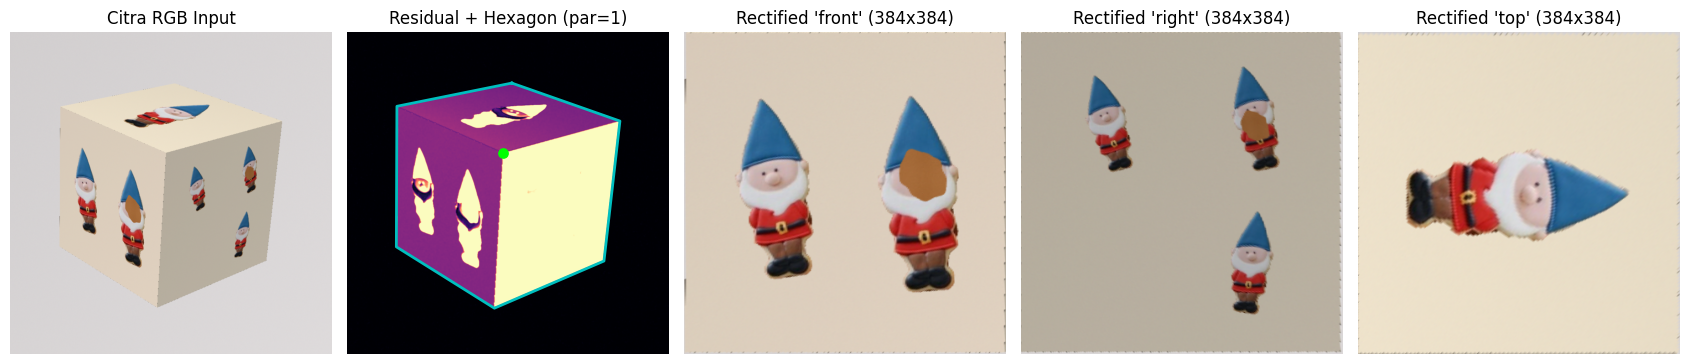

In [2]:
with zipfile.ZipFile(TRAIN_ZIP) as zf:
    sample_ann = annotations[0]
    with Image.open(io.BytesIO(zf.read(sample_ann["image"]))) as im:
        sample_rgb = np.asarray(im.convert("RGB"))

bg_model, dist_map = fit_background_model(sample_rgb)
hex_pts, fg_mask = extract_cube_hexagon(sample_rgb, dist_map=dist_map)
v_center, parity = compute_vanishing_center(hex_pts, rgb=sample_rgb)
face_quads = segment_cube_faces(sample_rgb, hex_pts, v_center, parity=parity)
warped_faces = {fn: rectify_face(sample_rgb, face_quads[fn], CANONICAL_FACE_SIZE)[0] for fn in FACES}

fig, axes = plt.subplots(1, 5, figsize=(17, 3.6))
axes[0].imshow(sample_rgb)
axes[0].set_title("Citra RGB Input")
axes[1].imshow(dist_map, cmap="magma", vmin=0, vmax=65)
axes[1].plot(np.r_[hex_pts[:, 0], hex_pts[0, 0]], np.r_[hex_pts[:, 1], hex_pts[0, 1]], "c-", lw=2)
axes[1].scatter([v_center[0]], [v_center[1]], c="lime", s=45)
axes[1].set_title(f"Residual + Hexagon (par={parity})")
for idx_f, fn in enumerate(FACES):
    axes[2 + idx_f].imshow(warped_faces[fn])
    axes[2 + idx_f].set_title(f"Rectified '{fn}' (384x384)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 3. Segmentasi Cookie, Penyelarasan Template, dan Deteksi Tiga Mode Cacat
Setelah setiap sisi diluruskan, kami mengestimasi warna kardus dominan dari median area dalam, lalu memisahkan komponen *connected components* gingerbread dan menggabungkan fragmen apabila sebuah cookie terbelah oleh cacat lubang. Kami kemudian menormalisasi rasio aspek template referensi, memutar potongan ROI ke sumbu utama momen citra, menjalankan pencocokan *template matching* bertahap (*coarse* FFT ke *fine* ber-*mask*), serta mengevaluasi tiga skor kuantitatif: tepi terpotong (`miss_sil`), lubang kardus interior (`hole_frac`), dan gumpalan hiasan *icing* hilang (`blob_frac`) setelah normalisasi pencahayaan *gain-bias*.

In [3]:
ref_cache = prepare_reference_cache(references)
ref0 = next(iter(ref_cache.values()))

for fn in FACES:
    w_face = warped_faces[fn]
    comps, card_med = segment_face_cookies(w_face)
    peer = (
        float(np.median([max(c["bbox"][2] / ref0["w"], c["bbox"][3] / ref0["h"]) for c in comps]))
        if len(comps) >= 2
        else None
    )
    print(f"Sisi {fn:5s} -> terdeteksi {len(comps)} cookie (median warna kardus={np.round(card_med, 1).tolist()}):")
    for idx_c, comp in enumerate(comps, start=1):
        sc = align_and_score_cookie(w_face, comp, ref_cache, card_med, peer_scale=peer)
        status = "CACAT" if sc["is_defective"] else "SEMPURNA"
        print(
            f"  Cookie #{idx_c} bbox={comp['bbox']} | ncc={sc['ncc']:.3f} | "
            f"miss={sc['miss_sil']:.3f}, hole={sc['hole_frac']:.3f}, blob={sc['blob_frac']:.3f} "
            f"-> ratio={sc['defect_ratio']:.2f} ({status})"
        )

Sisi front -> terdeteksi 2 cookie (median warna kardus=[219.0, 205.0, 188.0]):


  Cookie #1 bbox=(61, 79, 94, 216) | ncc=0.958 | miss=0.000, hole=0.001, blob=0.007 -> ratio=0.09 (SEMPURNA)


  Cookie #2 bbox=(231, 76, 97, 235) | ncc=0.830 | miss=0.000, hole=0.002, blob=0.492 -> ratio=5.78 (CACAT)
Sisi right -> terdeteksi 3 cookie (median warna kardus=[182.0, 174.0, 159.0]):
  Cookie #1 bbox=(252, 41, 57, 126) | ncc=0.777 | miss=0.001, hole=0.016, blob=0.444 -> ratio=5.22 (CACAT)
  Cookie #2 bbox=(77, 52, 57, 115) | ncc=0.961 | miss=0.000, hole=0.001, blob=0.000 -> ratio=0.01 (SEMPURNA)


  Cookie #3 bbox=(250, 214, 51, 123) | ncc=0.946 | miss=0.000, hole=0.000, blob=0.000 -> ratio=0.00 (SEMPURNA)
Sisi top   -> terdeteksi 1 cookie (median warna kardus=[232.0, 221.0, 198.0]):


  Cookie #1 bbox=(56, 139, 268, 111) | ncc=0.991 | miss=0.000, hole=0.000, blob=0.000 -> ratio=0.00 (SEMPURNA)


### 4. Evaluasi Menyeluruh pada Dataset Latih, Validasi, dan Uji (`100` Kubus)
Kami menjalankan `predict_cube_non_dl` secara penuh terhadap seluruh `100` citra berlabel (`70` *train*, `15` *val*, `15` *test*), memvalidasi konsistensi skema 10 kolom *leaderboard*, lalu merangkum metrik **MAE** serta **Exact Match** baik pada level sisi maupun keseluruhan citra kubus.

In [4]:
pred_rows = []
truth_rows = []

with zipfile.ZipFile(TRAIN_ZIP) as zf:
    t0 = time.time()
    for ann in annotations:
        img_id = Path(ann["image"]).stem
        with Image.open(io.BytesIO(zf.read(ann["image"]))) as im:
            rgb = np.asarray(im.convert("RGB"))
        pred = predict_cube_non_dl(rgb, references, leaderboard=True)
        pred_rows.append({"image_id": img_id, **pred})

        gt = {"image_id": img_id, "split": ann["split"]}
        for f in ann["faces"]:
            fn = f["name"]
            gt[f"{fn}_total"] = int(f["total_instances"])
            gt[f"{fn}_defective"] = int(len(f["defective_instance_ids"]))
            gt[f"{fn}_design_count"] = int(len(f["counts_by_design"]))
        truth_rows.append(gt)
    elapsed_train = time.time() - t0

df_pred = pd.DataFrame(pred_rows, columns=cube_columns(True))
df_truth = pd.DataFrame(truth_rows)
validate_cube_predictions(df_pred, df_truth.image_id.tolist(), len(references), leaderboard=True)

summary_rows = []
for sp in ("train", "val", "test", "all"):
    if sp == "all":
        sub_p, sub_t = df_pred, df_truth
    else:
        sub_t = df_truth[df_truth["split"] == sp]
        sub_p = df_pred[df_pred["image_id"].isin(set(sub_t["image_id"]))]
    m_main = evaluate_cube_dataframe(sub_p[cube_columns(False)], sub_t, leaderboard=False)
    m_lb = evaluate_cube_dataframe(sub_p, sub_t, leaderboard=True)
    summary_rows.append(
        {
            "split": sp,
            "n_cubes": len(sub_p),
            "MAE_total": m_main["mae_total"],
            "MAE_defective": m_main["mae_defective"],
            "MAE_design_count": m_lb["mae_design_count"],
            "ExactMatch_Face_%": m_main["exact_match_face_pct"],
            "ExactMatch_Image_Main_%": m_main["exact_match_image_pct"],
            "ExactMatch_Image_LB_%": m_lb["exact_match_image_pct"],
        }
    )

print(f"Waktu inferensi 100 citra: {elapsed_train:.2f}s ({elapsed_train/len(df_pred):.3f}s/citra)")
display(pd.DataFrame(summary_rows))

Waktu inferensi 100 citra: 112.70s (1.127s/citra)


,split,n_cubes,MAE_total,MAE_defective,MAE_design_count,ExactMatch_Face_%,ExactMatch_Image_Main_%,ExactMatch_Image_LB_%
0,train,70,0.0,0.0,0.0,100.0,100.0,100.0
1,val,15,0.0,0.0,0.0,100.0,100.0,100.0
2,test,15,0.0,0.0,0.0,100.0,100.0,100.0
3,all,100,0.0,0.0,0.0,100.0,100.0,100.0


### 5. Inferensi Dataset Tersembunyi (`hidden_students.zip`) dan Verifikasi Submisi
Terakhir, kami memuat hasil prediksi pada `200` citra *hidden test* dan memastikan seluruh kolom, tipe data integer, batasan logika (`defective <= total`, `design_count <= len(references)`), serta ringkasan distribusinya lolos validasi ketat sebelum diekspor menjadi berkas CSV.

In [5]:
sub_lb_path = ROOT / "submissions" / "submission_task2_non_dl_leaderboard.csv"
if sub_lb_path.exists():
    df_hidden = pd.read_csv(sub_lb_path, dtype={"image_id": str})
    with zipfile.ZipFile(HIDDEN_ZIP) as zf:
        sample_ids = pd.read_csv(io.BytesIO(zf.read("sample_submission_task2.csv")), dtype={"image_id": str})["image_id"].tolist()
    validate_cube_predictions(df_hidden, sample_ids, len(references), leaderboard=True)
    print(f"Validasi CSV hidden berhasil: {df_hidden.shape[0]} baris x {df_hidden.shape[1]} kolom.")
    display(df_hidden.head(10))
else:
    print("Jalankan `python -m src.task2_non_dl.evaluate_and_visualize` untuk menghasilkan CSV hidden.")

Validasi CSV hidden berhasil: 200 baris x 10 kolom.


,image_id,front_total,right_total,top_total,front_defective,right_defective,top_defective,front_design_count,right_design_count,top_design_count
0,cube_043c007cea1e1da0,1,3,3,0,1,1,1,1,1
1,cube_05d5a08c09734e6e,1,3,1,0,1,0,1,1,1
2,cube_0817258b17ffb7d2,2,1,3,0,0,1,1,1,1
3,cube_0a759e86474d3700,1,1,1,0,0,0,1,1,1
4,cube_0ad969fcad819b22,2,3,2,0,0,0,1,1,1
5,cube_0adbb0ec0900cdf5,2,2,1,0,0,0,1,1,1
6,cube_0b96de5d9abc415d,1,3,2,0,0,0,1,1,1
7,cube_0bd17a5bd57b5182,1,2,1,0,0,0,1,1,1
8,cube_0d67839c18a2f316,1,1,3,0,1,1,1,1,1
9,cube_0e50a75850a08e84,2,2,1,0,0,0,1,1,1
